---
**UNIVERSIDAD NACIONAL DE ASUNCIÓN**  
**FACULTAD DE INGENIERÍA**

# ROBÓTICA II
# TRABAJO PRÁCTICO  2026S2
## Robot recolector de limones «Arturito R2D2»


---
**Grupo 2:**

 Pablo Junior Otazú Luján

 Pedro Daniel Vera Ramírez

 Héctor Dejesús Velázquez Ojeda

 Mathias Ramón Aguilar Delvalle  

**Entrega 2:** Diseño de la plataforma y primeros montajes  

**Fecha de revisión:** 27/09/2026

  **Versión:** 2.1




---
## 1. Introducción

El proyecto consiste en una plataforma móvil para un robot recolector de limones. La plataforma debe alojar el manipulador, la tracción, el suministro eléctrico, los controladores y los sensores. En la recolección de cítricos se integran locomoción, percepción y manipulación, como muestran los antecedentes [1].

Esta entrega registra el diseño y los primeros montajes mecánicos, junto con una propuesta de ubicación de sensores y controladores. La instalación eléctrica y la integración de dichos dispositivos sobre el chasis siguen pendientes. La pareja de cámaras sí cuenta con un montaje provisional externo para pruebas de banco. Las pruebas aisladas de sensores se distinguen del funcionamiento del robot completo.


---
## 2. Diseño y arquitectura de la plataforma

### 2.1 Geometría y locomoción

La estructura preliminar es de madera terciada de 10 mm. Su base mide aproximadamente 400 × 400 mm y la altura estructural es de unos 220 mm. Se eligió este material por disponibilidad, costo y facilidad de mecanizado durante el prototipado. Las dimensiones corresponden al diseño y al montaje inicial descritos por el grupo; se deberán medir nuevamente cuando se fijen todos los componentes.

La locomoción contempla dos ruedas motrices de aproximadamente 150 mm de diámetro, accionadas por motores DC independientes, y dos ruedas locas. El brazo se representa sobre la cubierta superior en el CAD; su estabilidad con el brazo extendido no ha sido validada. La batería y otros elementos pesados se proyectan bajos y próximos al centro. Esta decisión busca reducir el riesgo de vuelco.

| Parámetro de diseño | Valor preliminar |
|---|---:|
| Base | 400 × 400 mm |
| Altura de la estructura | ≈ 220 mm |
| Espesor de la madera | 10 mm |
| Ruedas | 2 motrices + 2 locas |
| Diámetro de rueda motriz | ≈ 150 mm |

### 2.2 Modelo CAD

La Fig. 1 muestra el modelo preliminar. El brazo dibujado representa la disposición buscada; la imagen no acredita por sí sola su montaje o una prueba de cargas.

<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1vM6j6cem82ydQRsOmDngsELM6Hycx1QT" width="700" />
  <p><b>Fig. 1.</b> Diseño mecánico preliminar de la plataforma móvil con el brazo robótico.</p>
</div>

### 2.3 Diagrama de bloques

La Fig. 2 separa la comunicación usada en los ensayos de banco de la integración prevista en el robot. En los ensayos, el ESP32 adquiere señales y el micro-ROS Agent comunica sus publicaciones a ROS 2 Humble en el PC [2, 3]. La Raspberry Pi 5 figura en el esquema como controlador de alto nivel propuesto para la plataforma. Su prueba de banco con dos cámaras se documenta por separado en la sección 4.5


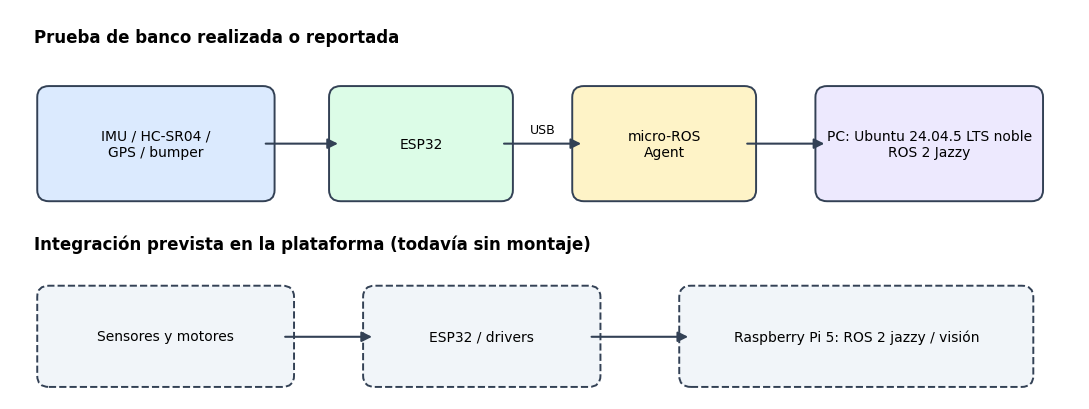

In [1]:
# Figura 2. Ejecutar esta celda para regenerar el diagrama de arquitectura.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.set_xlim(0, 11)
ax.set_ylim(0, 4.2)
ax.axis('off')

def box(x, y, w, h, label, color, dashed=False):
    patch = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.12',
                           edgecolor='#334155', facecolor=color, linewidth=1.4,
                           linestyle='--' if dashed else '-')
    ax.add_patch(patch)
    ax.text(x + w/2, y + h/2, label, ha='center', va='center', fontsize=10)

def arrow(x1, y1, x2, y2, label=''):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle='-|>',
                                 mutation_scale=15, linewidth=1.5, color='#334155'))
    if label:
        ax.text((x1+x2)/2, (y1+y2)/2 + .12, label, ha='center', fontsize=9)

ax.text(.25, 3.85, 'Prueba de banco realizada o reportada', fontsize=12, weight='bold')
box(.4, 2.25, 2.2, 1, 'IMU / HC-SR04 /\nGPS / bumper', '#dbeafe')
box(3.4, 2.25, 1.65, 1, 'ESP32', '#dcfce7')
box(5.9, 2.25, 1.65, 1, 'micro-ROS\nAgent', '#fef3c7')
box(8.4, 2.25, 2.1, 1, 'PC: Ubuntu 24.04.5 LTS noble\nROS 2 Jazzy', '#ede9fe')
arrow(2.6, 2.75, 3.4, 2.75)
arrow(5.05, 2.75, 5.9, 2.75, 'USB')
arrow(7.55, 2.75, 8.4, 2.75)
ax.text(.25, 1.62, 'Integración prevista en la plataforma (todavía sin montaje)', fontsize=12, weight='bold')
box(.4, .25, 2.4, .85, 'Sensores y motores', '#f1f5f9', True)
box(3.75, .25, 2.2, .85, 'ESP32 / drivers', '#f1f5f9', True)
box(7.0, .25, 3.4, .85, 'Raspberry Pi 5: ROS 2 jazzy / visión', '#f1f5f9', True)
arrow(2.8, .67, 3.75, .67)
arrow(5.95, .67, 7.0, .67)
fig.tight_layout()
plt.show()


**Fig. 2.** Arquitectura de las pruebas de sensores por ESP32 y micro-ROS (fila superior) y propuesta de integración en la plataforma (fila inferior, bloques discontinuos). Las cuatro familias de sensores no se han demostrado funcionando simultáneamente.

### 2.4 Alimentación prevista

El diseño considera una batería nominal de 36 V / 4400 mAh y conversión DC-DC.


---
## 3. Selección de componentes

La tabla explica la función y el criterio de cada elección.

| Componente | Cant. | Función y criterio de selección | Estado para esta entrega |
|---|---:|---|---|
| Madera terciada de 10 mm | — | Prototipo mecanizable y disponible; verificar rigidez con la carga real. | Estructura montada según fotos |
| Ruedas motrices ≈ 150 mm y ruedas locas | 2 + 2 | Tracción independiente y dos apoyos adicionales; verificar alineación y espacio libre. | Primer montaje fotografiado |
| Motores DC y soportes | 2 | Tracción; la selección definitiva requiere masa total, pendiente, velocidad, relación de transmisión y par de arranque. | Soportes/motores fotografiados; desempeño sin medir |
| Raspberry Pi 5 y dos cámaras | 1 + 2 | Procesamiento de visión estéreo; separación y orientación deben mantenerse fijas al calibrar. | Dos cámaras conectadas a la Pi en soporte provisional de cartón; sin montaje en chasis |
| ESP32 | 2 previstos | Adquisición y control de bajo nivel; uno se usó para pruebas separadas de banco con micro-ROS. | Sin instalación definitiva en chasis |
| IMU MPU-6050 | 1 | Movimiento/orientación; interfaz I²C y fijación rígida próxima al centro. | Ensayo de banco; montaje pendiente |
| HC-SR04 | 3 previstos | Distancias próximas; orientar hacia zonas de aproximación y evitar interferencias entre disparos. | Un canal probado en banco; tres sin integración conjunta |
| GPS Fastrax UP501A03 | 1 | Posición exterior; interfaz serial NMEA y visibilidad del cielo. | Tramas recibidas sin posición válida; montaje pendiente |
| Bumpers | 4 previstos | Contacto físico; situar en zonas de posible choque. | Prueba aislada reportada; conjunto sin montar |
| LiDAR, drivers, batería y convertidores | Según diseño | Navegación y alimentación; modelos y corrientes deben comprobarse antes del cableado. | Integración física pendiente |




---
## 4. Primeros montajes y posición de los equipos

### 4.1 Estructura

Las fotos muestran el proceso de armado y la estructura principal de madera. La base, los laterales y la cubierta dejan volumen interior para futuros controladores y alimentación.

<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1T08-VRQso1N3w3ayOs99_Cgczwr6T_ke" width="650" />
  <p><b>Fig. 3.</b> Proceso de fabricación y montaje de la estructura de la plataforma móvil.</p>
</div>

<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1a2--jwWoKc5I3s-7jUoP52QiGPE0XO0A" width="650" />
  <p><b>Fig. 4.</b> Estructura principal de la plataforma móvil ensamblada.</p>
</div>

### 4.2 Ruedas, motores y transmisión

Se fotografió el montaje inicial de motores DC sobre soportes metálicos y la distribución de dos ruedas motrices con dos ruedas locas.

<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1fgZnLw17l21XwZ-X76AHQOl3hqNBfcCO" width="650" />
  <p><b>Fig. 5.</b> Montaje del motor de tracción y su soporte metálico sobre la estructura.</p>
</div>

<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1YRLfVEeglXUgl1yUgKYqIzyt26Kzh2p4" width="650" />
  <p><b>Fig. 6.</b> Disposición de las ruedas motrices y ruedas locas de la plataforma móvil.</p>
</div>

### 4.3 Estado físico del prototipo

<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1PRqzP_4y-VSwLBopzwlTvU06r-O7urWF" width="650" />
  <p><b>Fig. 7.</b> Estado preliminar del montaje físico de la plataforma móvil.</p>
</div>

### 4.4 Ubicaciones propuestas de sensores y controladores

| Equipo | Ubicación propuesta | Motivo | Montaje sobre plataforma |
|---|---|---|---|
| Raspberry Pi 5, ESP32, drivers | Interior, con acceso y separación entre señales y potencia | Protección, mantenimiento y cableado | Pendiente |
| Dos cámaras | Zona frontal/elevada por definir | Campo de visión y base estéreo rígida | Montaje de banco realizado; ubicación en chasis pendiente |
| IMU | Cerca del centro, fijada rígidamente | Referencia estable del movimiento | Pendiente |
| GPS | Parte superior despejada | Mejor recepción satelital | Pendiente |
| HC-SR04 ×3 | Frente y laterales, orientación por ajustar | Cobertura de obstáculos próximos | Pendiente |
| Bumpers ×4 | Puntos de posible contacto por definir | Detección física | Pendiente |
| LiDAR | Zona elevada, sin obstrucción en su campo | Percepción del entorno | Pendiente |

Las posiciones del cuadro describen la instalación final prevista en el robot. La fijación definitiva dependerá de los ensayos de visibilidad, vibración y alcance de cableado.

### 4.5 Montaje preliminar de visión estéreo fuera del robot

La Fig. 8 muestra dos cámaras conectadas por cables flexibles a una Raspberry Pi 5. Ambas se fijaron de manera provisional a un soporte de cartón, frente a un tablero de ajedrez usado en las pruebas. No es el soporte definitivo del robot; la separación entre cámaras y su rigidez aún deben definirse y comprobarse para el montaje final.

<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1gdYDLCUNt5rxs1_ibfdvblPRUvNI6tH3" width="650" />
  <p><b>Fig. 8.</b> Montaje provisional de las dos cámaras y la Raspberry Pi 5 para pruebas de banco. </p>
</div>

En el [video de la prueba de visión estéreo en RViz](https://drive.google.com/file/d/1KrkN7QlL3RtME--b7XzbBPz_Zft95-GM/view) se observa una visualización de nube de puntos y luego el montaje físico. El video documenta la ejecución preliminar; no permite concluir todavía que las distancias reconstruidas sean exactas ni acredita instalación en la plataforma móvil.



---
## 5. Lecturas preliminares de sensores con ROS 2

Las lecturas anteriores se obtuvieron fuera de la plataforma con ESP32, micro-ROS y ROS 2 Humble en Ubuntu 22.04.5. Una publicación ROS 2 demuestra comunicación; no demuestra calibración, prueba de las cantidades previstas ni operación integrada [2, 3].

| Sensor pedido | Evidencia técnica disponible en el trabajo previo
|---|---|
| IMU ×1 | MPU-6050; publicación de IMU reportada a ≈ 20 Hz. El [video de banco](https://drive.google.com/file/d/1SUYm2XXXjJeQdNDJxjzFTL86Y-jd5rVf/view) muestra el ESP32 y RViz durante la demostración.
| Ultrasonidos ×3 | Una unidad HC-SR04 publicó en `/ultrasonic/range` durante una prueba de banco.
| GPS ×1 | El Fastrax emitió tramas NMEA por UART. RMC en estado `V` y GGA sin fix durante la prueba.
| Bumpers ×3 | Se planteó un estado lógico 0 libre / 1 pulsado en la prueba aislada.


---
## 6. Evidencias y participación

### 6.1 Fotografías y modelo

Las Figs. 1 y 3–7 conservan los enlaces de la carpeta compartida de imágenes del Colab original; la Fig. 8 está en la carpeta «Entrega 2» y documenta el soporte provisional de las cámaras. Cada pie distingue CAD, montaje mecánico y prueba externa al robot.

### 6.2 Evidencias multimedia de sensores

[Lista de reproducción de pruebas de sensores](https://www.youtube.com/playlist?list=PLa3OAG4TCwaY). El enlace general ya existía en el cuaderno. Falta identificar qué video muestra IMU, HC-SR04, GPS y cada bumper, y comprobar que el enlace funciona, que no dirige a Shorts y que los videos tienen audio y permiten leer la salida ROS 2.

| Prueba | Enlace individual o tiempo dentro de la lista | Estado documental |
|---|---|---|
| IMU ×1 | [Video de prueba de banco: ESP32 y RViz](https://drive.google.com/file/d/1SUYm2XXXjJeQdNDJxjzFTL86Y-jd5rVf/view) | Video incorporado; faltan capturas legibles de tópico y frecuencia |
| HC-SR04 ×1 probado | Por identificar en la lista | Pendiente de vincular |
| HC-SR04 restantes ×2 | Sin video identificado | Pendiente de prueba/documentación |
| GPS ×1 | Por identificar en la lista | Aclarar que aún no hay fix válido |
| Bumpers ×4 | Sin enlaces individuales identificados | Pendiente de verificar los cuatro |
| Visión estéreo (adicional) | [Foto del montaje](https://drive.google.com/file/d/1gdYDLCUNt5rxs1_ibfdvblPRUvNI6tH3/view) · [Video con RViz](https://drive.google.com/file/d/1KrkN7QlL3RtME--b7XzbBPz_Zft95-GM/view) | Demostración preliminar en banco; precisión y montaje definitivo pendientes |

### 6.3 Carpeta compartida

[Carpeta de trabajo «Entrega 2»](https://drive.google.com/drive/folders/1uPors1LMvXUQwBMtc-2MlfkU0qH8Lhx4). Allí se encuentra este Colab. Comprobar que el docente pueda abrir el cuaderno y las evidencias multimedia desde su cuenta; el acceso al contenedor por sí solo no prueba que cada video esté incluido.



---
## 7. Referencias

[1] H. Yin et al., «Development, integration, and field evaluation of an autonomous citrus-harvesting robot», *Journal of Field Robotics*, vol. 40, pp. 1363–1387, 2023. [doi:10.1002/rob.22178](https://doi.org/10.1002/rob.22178). Citada en la introducción.

[2] micro-ROS, [Micro-ROS Agent: paquete oficial](https://github.com/micro-ROS/micro-ROS-Agent). Citado en la arquitectura y en las pruebas de banco.

[3] ROS 2 Humble, [Understanding topics](https://docs.ros.org/en/humble/Tutorials/Beginner-CLI-Tools/Understanding-ROS2-Topics/Understanding-ROS2-Topics.html). Citado para observación y frecuencia de tópicos.

